# Lab 8 - Edge Detection

**Image Processing Laboratory**

This solution applies Sobel, Prewitt, and Canny edge detection to `Butterfly.jpg`, then compares Canny using all three threshold pairs in the task sheet. The reference notebook used `kid1.jpg`; this uses a different supplied image. Keep `Butterfly.jpg` beside this notebook when running it.

In [1]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

IMAGE_PATH = Path('Butterfly.jpg')
image_bgr = cv2.imread(str(IMAGE_PATH), cv2.IMREAD_COLOR)
if image_bgr is None:
    raise FileNotFoundError(f'Could not load {IMAGE_PATH.resolve()}')
image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (5, 5), 0)
print(f'Image: {IMAGE_PATH.name}')
print(f'Dimensions: {gray.shape[1]} x {gray.shape[0]} pixels')
print(f'OpenCV version: {cv2.__version__}')

Image: Butterfly.jpg
Dimensions: 800 x 532 pixels
OpenCV version: 5.0.0


## Task 1 - Apply the three edge detectors

Sobel and Prewitt estimate horizontal and vertical intensity changes; their gradient magnitudes combine both directions. Canny smooths the image, computes gradients, thins edges with non-maximum suppression, then uses two thresholds and hysteresis to retain connected edges.

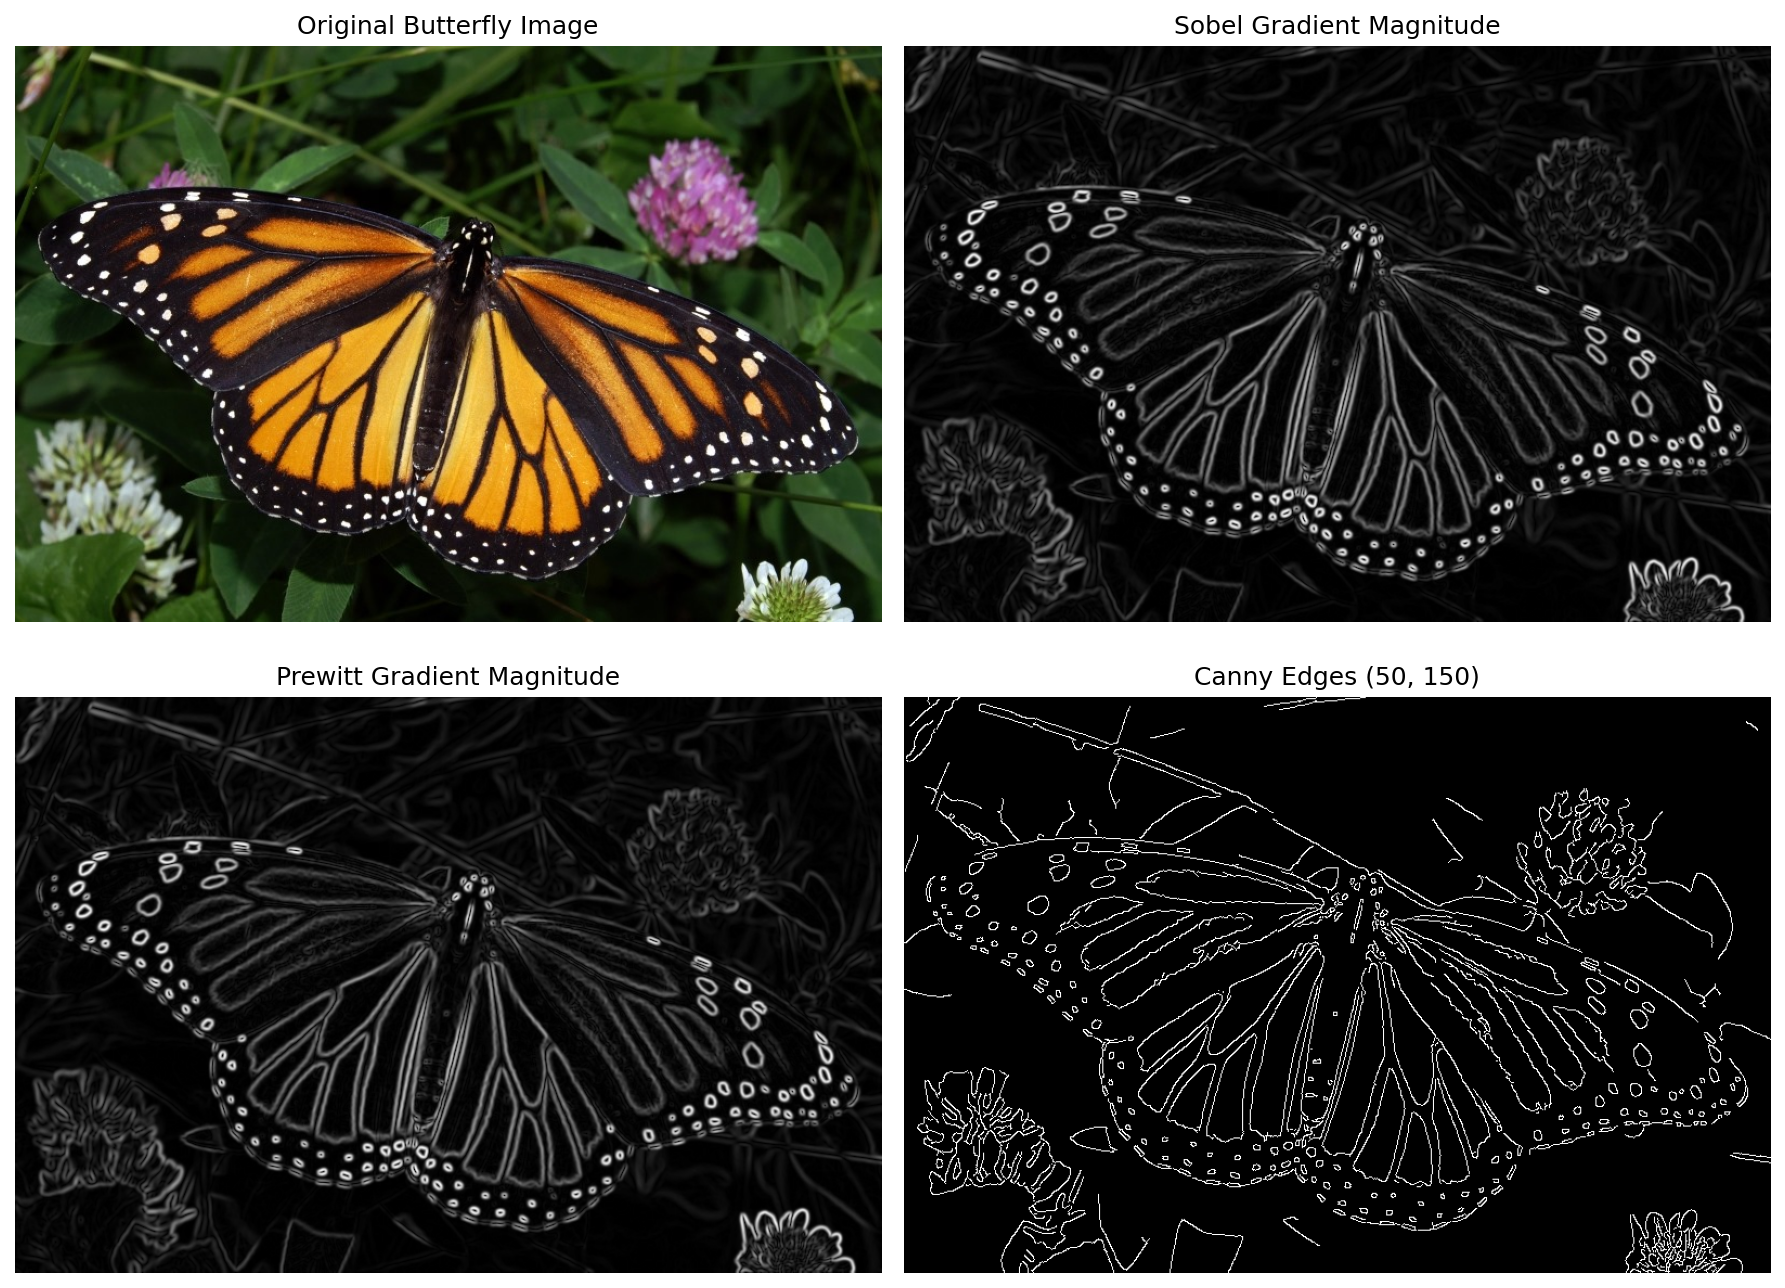

In [2]:
# Sobel: 3 x 3 derivative filters
sobel_x = cv2.Sobel(blurred, cv2.CV_32F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(blurred, cv2.CV_32F, 0, 1, ksize=3)
sobel_magnitude = cv2.magnitude(sobel_x, sobel_y)
sobel_edges = cv2.normalize(sobel_magnitude, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

# Prewitt: manually defined 3 x 3 derivative kernels
prewitt_x_kernel = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], dtype=np.float32)
prewitt_y_kernel = np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]], dtype=np.float32)
prewitt_x = cv2.filter2D(blurred, cv2.CV_32F, prewitt_x_kernel)
prewitt_y = cv2.filter2D(blurred, cv2.CV_32F, prewitt_y_kernel)
prewitt_magnitude = cv2.magnitude(prewitt_x, prewitt_y)
prewitt_edges = cv2.normalize(prewitt_magnitude, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

# Canny reference thresholds
canny_edges = cv2.Canny(blurred, 50, 150)
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes[0, 0].imshow(image_rgb); axes[0, 0].set_title('Original Butterfly Image')
axes[0, 1].imshow(sobel_edges, cmap='gray', vmin=0, vmax=255); axes[0, 1].set_title('Sobel Gradient Magnitude')
axes[1, 0].imshow(prewitt_edges, cmap='gray', vmin=0, vmax=255); axes[1, 0].set_title('Prewitt Gradient Magnitude')
axes[1, 1].imshow(canny_edges, cmap='gray', vmin=0, vmax=255); axes[1, 1].set_title('Canny Edges (50, 150)')
for ax in axes.ravel(): ax.axis('off')
fig.tight_layout()
plt.show()

### Task 1 observations

Sobel and Prewitt both show boundaries as bright gradient responses. Sobel weights the center row and column more heavily, adding some smoothing; Prewitt uses uniform kernel weights. Canny creates thinner binary contours through non-maximum suppression and hysteresis edge linking.

## Task 2 - Compare Canny thresholds

The required low/high threshold pairs are (30, 90), (50, 150), and (100, 200). Each uses the same blurred grayscale image.

Canny edge-pixel counts out of 425600 total pixels:
  ( 30,  90): 33,792 ( 7.94%)
  ( 50, 150): 23,434 ( 5.51%)
  (100, 200): 16,823 ( 3.95%)


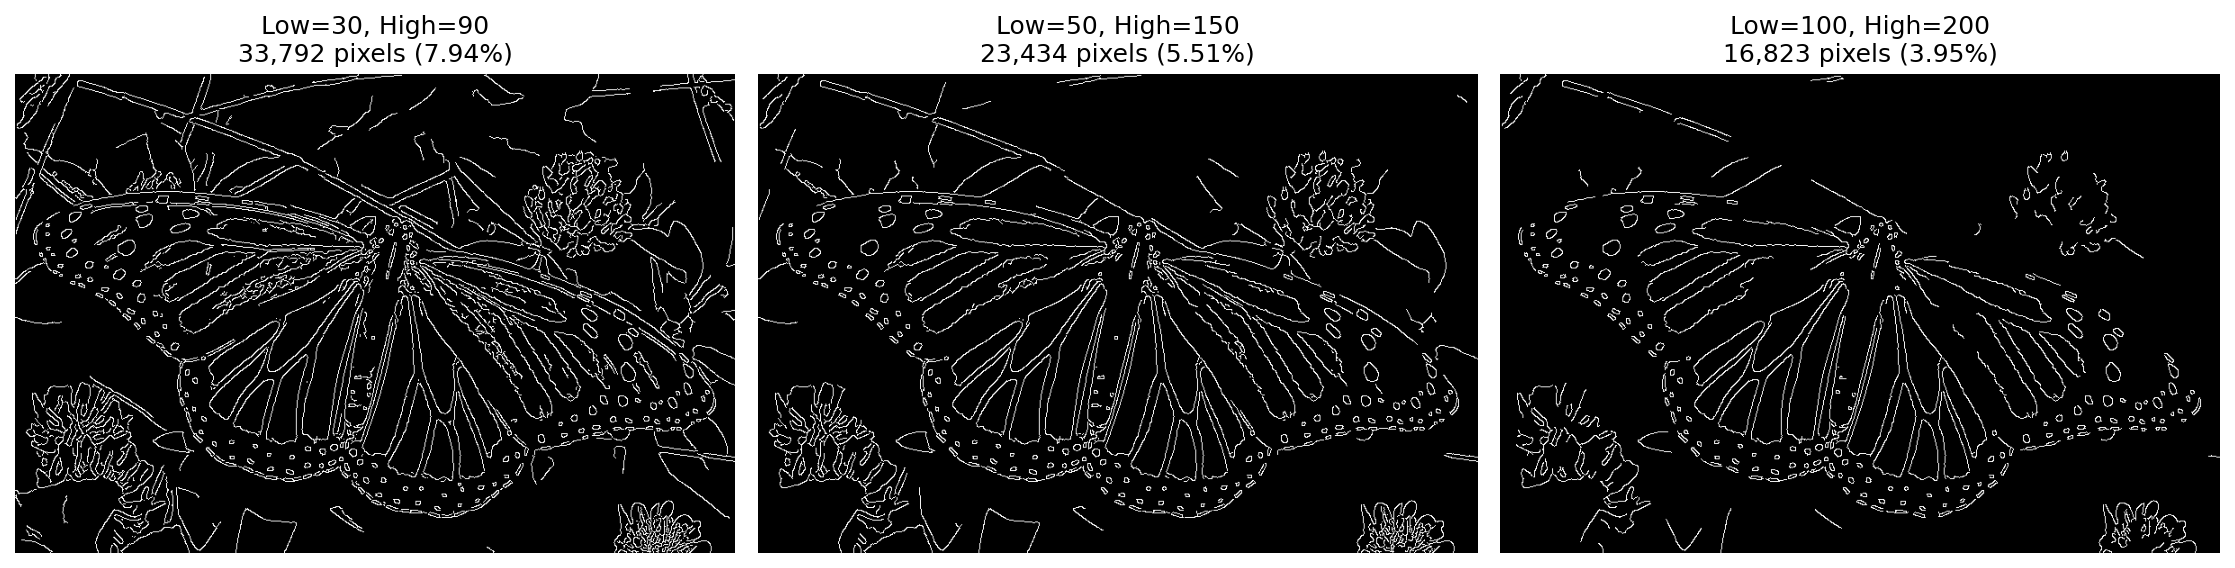

In [3]:
threshold_pairs = [(30, 90), (50, 150), (100, 200)]
canny_threshold_results = []
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (low, high) in zip(axes, threshold_pairs):
    edge_map = cv2.Canny(blurred, low, high)
    edge_count = int(cv2.countNonZero(edge_map))
    edge_percent = 100.0 * edge_count / edge_map.size
    canny_threshold_results.append((low, high, edge_map, edge_count, edge_percent))
    ax.imshow(edge_map, cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'Low={low}, High={high}\n{edge_count:,} pixels ({edge_percent:.2f}%)')
    ax.axis('off')
fig.tight_layout()
plt.show()
print(f'Canny edge-pixel counts out of {gray.size} total pixels:')
for low, high, _, edge_count, edge_percent in canny_threshold_results:
    print(f'  ({low:3d}, {high:3d}): {edge_count:6,d} ({edge_percent:5.2f}%)')

### Task 2 explanation

The lower pair (30, 90) is more permissive, so it generally keeps more weak edges and fine detail, with a greater chance of retaining texture or noise. Increasing the thresholds to (50, 150) removes weaker responses. The highest pair (100, 200) is most selective and tends to produce a cleaner, sparser map, but may miss low-contrast boundaries. Hysteresis keeps a weak edge when it connects to a strong edge. The printed counts give the measured comparison for this image.

## Conclusion

Sobel and Prewitt provide gradient-strength maps, while Canny returns thin binary contours. Raising Canny thresholds trades weak or fine edges for a sparser result. The notebook reports edge-pixel counts so the comparison is both visual and measurable.